Nama: Adisti Eka Nabila

NIM: 24031554119

Mata Kuliah: Graf Sains Data

In [ ]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "....")


def add_friend(driver, name, friend_name):
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)
        """,
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )


def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend_name
        ORDER BY friend_name
        """,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend_name"])


with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil!")

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("\nTeman Arthur:")
    print_friends(driver, "Arthur")

### 1. Apa nama database yang digunakan pada tutorial ini?

Database yang digunakan yaitu neo4j. Hal ini dikarenakan terlihat pada parameter database_=”neo4j” dalam fungsi add_friend() an print_friend(). Database tersebut digunakan untuk menyimpan dan mengambil data pertemana melalui python driver.

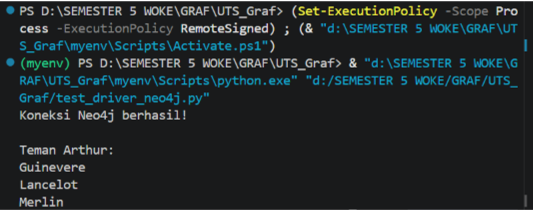


2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance! 

Database lain dalam satu instance dapat diakses dengan menentukan nama database saat membuat
session melalui parameter database_ pada driver.execute_query(). Beberapa Cypher yang dapat
digunakan untuk mengelola data graf:
1.	CREAT: membuat node atau relationship baru
2.	MATCH: mencari node dan relationship berdasarkan pola tertentu
3.	MERGE: membuat data jka belum tersedia atau menggunakan data yag sudah cocok
4.	SET: menambahkan atau mengubah property node maupun relationship
5.	DELETE: menghapus node atau relationship
Dengan mengganti database yang dituju dapat melakukan pengaksesan pada database berbeda dalam satu instance.


3. Apa jenis graf pertemanan yang telah dibuat di sini? 

Graf pertemana yang dibuat adalah graf berarah yang dimana graf memiliki node berlabel person sebagai representasi orang dan relationship KNOWS sebagai hubungan pertemanan.
(a)-[:KNOWS]->(friend)
Dari pola tersebut menunjukkan arah hubungan dari a atau person menuju temannya dan bukan relasi sebaliknya.


In [2]:
import argparse
import os
import sys
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

In [2]:
import neo4j
print(neo4j.__version__)

6.4.1


In [3]:
def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j",
        help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="neo4j",
        help="Password Neo4J (default: neo4j)"
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)"
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)"
    )
    return parser.parse_args()

In [ ]:
args = argparse.Namespace(
    user="neo4j",
    password="....",
    bolt="neo4j://127.0.0.1:7687",
    source="data"
)

csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

print(f"File ditemukan: {csv_file_path}")

File ditemukan: data\events.csv


In [5]:
try:
    driver = GraphDatabase.driver(
        args.bolt,
        auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

Koneksi ke Neo4j berhasil!


In [6]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

In [7]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [9]:
batch_size = 10000

with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")

    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    total_rows = sum(
        1 for _ in open(csv_file_path, encoding="utf-8")
    ) - 1

    total_chunks = (total_rows // batch_size) + 1

    print(f"Jumlah baris data: {total_rows}")
    print(f"Jumlah batch: {total_chunks}")
    print("Memulai proses impor data ke Neo4j...")

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Jumlah baris data: 2756101
Jumlah batch: 276
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [03:50<00:00,  1.20it/s]

Proses impor berhasil.


Melakukan impor dataset RetailRocket ke database Neo4j menggunakan Python. Dataset events.csv dibaca menggunakan Pandas dengan ukuran batch 10.000 baris agar proses impor lebih efisien. Selanjutnya, membuat constraint untuk memastikan visitorId dan itemId bersifat unik, kemudian membentuk simpul Visitor dan Item serta relasi berdasarkan jenis aktivitas pengguna, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Setiap relasi menyimpan informasi waktu kejadian (timestamp), sedangkan relasi BOUGHT juga menyimpan transactionId. Sebelum impor dilakukan, koneksi ke Neo4j diverifikasi untuk memastikan database dapat diakses.

## 1.Penentuan P1 training dan P2 testing filter pada timestamp

In [4]:
df = pd.read_csv("data/events.csv")

df["tanggal"] = pd.to_datetime(
    df["timestamp"],
    unit="ms"
)

print("Jumlah baris:", len(df))
print("Tanggal awal:", df["tanggal"].min())
print("Tanggal akhir:", df["tanggal"].max())

Jumlah baris: 2756101
Tanggal awal: 2015-05-03 03:00:04.384000
Tanggal akhir: 2015-09-18 02:59:47.788000


In [ ]:
jumlah_harian = (
    df.groupby(df["tanggal"].dt.date)
      .size()
      .rename("jumlah_interaksi")
)

# Menghitung jumlah kumulatif interaksi
kumulatif = jumlah_harian.cumsum()

target_training = len(df) * 0.70

tanggal_batas = (
    (kumulatif - target_training)
    .abs()
    .idxmin()
)

print("Total interaksi:", len(df))
print("Target training 70%:", round(target_training))
print("Tanggal batas P1:", tanggal_batas)
print("Interaksi kumulatif sampai batas:", kumulatif.loc[tanggal_batas])
print("Persentase training:", round(kumulatif.loc[tanggal_batas] / len(df) * 100, 2), "%")

Total interaksi: 2756101
Target training 70%: 1929271
Tanggal batas P1: 2015-08-02
Interaksi kumulatif sampai batas: 1929708
Persentase training: 70.02 %


Pembagian periode training ditentukan dengan mencari tanggal yang menghasilkan jumlah interaksi kumulatif paling mendekati target 70% dari total 2.756.101 interaksi. Tanggal batas yang diperoleh adalah 2 Agustus 2015, dengan 1.929.708 interaksi atau 70,02% dari total data. Oleh karena itu, periode P1 ditetapkan sebagai data training dari 3 Mei–2 Agustus 2015, sedangkan P2 digunakan sebagai data testing dari 3 Agustus–18 September 2015.

## 2. lalu simpan hasil filter di file csv

membagi dataset menjadi dua periode, yaitu P1 sebagai data training (3 Mei–2 Agustus 2015) dan P2 sebagai data testing (3 Agustus–18 September 2015). Kedua periode disaring berdasarkan tanggal masing-masing data disimpan dalam file CSV terpisah.

In [ ]:
p1 = df[
    (df["tanggal"] >= "2015-05-03") &
    (df["tanggal"] < "2015-08-03")
].copy()

p2 = df[
    (df["tanggal"] >= "2015-08-03") &
    (df["tanggal"] < "2015-09-19")
].copy()

p1.drop(columns=["tanggal"], inplace=True)
p2.drop(columns=["tanggal"], inplace=True)

p1.to_csv("data/events_P1_training.csv", index=False)
p2.to_csv("data/events_P2_testing.csv", index=False)

print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))
print("Total data:", len(p1) + len(p2))

print("\nPersentase P1:", round(len(p1) / len(df) * 100, 2), "%")
print("Persentase P2:", round(len(p2) / len(df) * 100, 2), "%")

assert len(p1) + len(p2) == len(df), "Jumlah data tidak sesuai!"
print("\nValidasi berhasil")

Jumlah data P1: 1929708
Jumlah data P2: 826393
Total data: 2756101

Persentase P1: 70.02 %
Persentase P2: 29.98 %

Validasi berhasil


Hasil pembagian dataset menunjukkan bahwa P1 berisi 1.929.708 interaksi (70,02%) dan P2 berisi 826.393 interaksi (29,98%), dari total 2.756.101 interaksi. Kedua periode berhasil disimpan ke file CSV terpisah, dan hasil validasi menunjukkan bahwa jumlah data P1 dan P2 sama dengan jumlah data awal.

In [36]:
df_p1 = pd.read_csv("data/events_P1_training.csv")

print("Nama kolom:", df_p1.columns.tolist())
print(df_p1.head())

Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN


## 3. Lakukan query untuk mendapatkan komposisi subraph

In [ ]:
batas_p1_p2 = pd.Timestamp("2015-08-03").timestamp() * 1000

print("Batas timestamp P1:", int(batas_p1_p2))

Batas timestamp P1: 1438560000000


In [ ]:
URI = "bolt://localhost:7687"
AUTH = ("neo4j", "adistiebil123")

driver = GraphDatabase.driver(URI, auth=AUTH)
batas_timestamp = 1438560000000

with driver.session(database="neo4j") as session:

    query_node = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE r.timestamp < $batas
    RETURN
        count(DISTINCT v) AS Jumlah_Visitor,
        count(DISTINCT i) AS Jumlah_Item
    """

    hasil_node = session.run(
        query_node, batas=batas_timestamp
    ).single()

    print("Jumlah Visitor:", hasil_node["Jumlah_Visitor"])
    print("Jumlah Item:", hasil_node["Jumlah_Item"])

    query_relasi = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE r.timestamp < $batas
    RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah
    ORDER BY Jenis_Relasi
    """

    hasil_relasi = session.run(
        query_relasi, batas=batas_timestamp
    )

    print("\nJumlah Relasi:")
    for record in hasil_relasi:
        print(record["Jenis_Relasi"], ":", record["Jumlah"])

Jumlah Visitor: 979136
Jumlah Item: 200994

Jumlah Relasi:
ADDED_TO_CART : 47572
BOUGHT : 15640
VIEWED : 1866496


Hasil tersebut menunjukkan bahwa interaksi paling banyak berupa aktivitas melihat produk (VIEWED), sedangkan aktivitas pembelian (BOUGHT) memiliki jumlah paling sedikit. Komposisi subgraf P1 didominasi oleh aktivitas melihat produk dibandingkan aktivitas menambahkan produk ke keranjang maupun membeli produk.

Query digunakan untuk mendapat komposisi subgraf P1 berdasarkan periode yang ditentukan. MATCH (v:Visitor)-[r]->(i:Item) digunakan untuk mencari simpul visitor dan item beserta relasi yang menghubungkan visitor dengan item. WHERE r.timestamp < $batas menayring relasi p1 berdasarkan batas waktu. count(DISTINCT v) dan count(DISTINCT i) diguankan untuk menghitung jumlah visitor dan item. type(r) digunkan untuk mengetahui jenis relasi, sedangkan count(r) menghitung jumlah relasi pada setiap jenisnya. ORDER BY Jenis_Relasi mengurutkan hasil berdasarka jenis relasi.

## 4 Vector Space Modelling (VSM) user

In [60]:
df_p1 = pd.read_csv("data/events_P1_training.csv")

print("Nama kolom:", df_p1.columns.tolist())
print(df_p1.head())

Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN


In [7]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from matplotlib.lines import Line2D
from sklearn.feature_extraction.text import CountVectorizer


df_p1 = pd.read_csv("data/events_P1_training.csv")
df_p1["itemid"] = df_p1["itemid"].astype(str)

# Membentuk VSM user-item
user_item = df_p1.groupby("visitorid")["itemid"].apply(
    lambda x: " ".join(x)
)

vectorizer = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    binary=True
)

vsm_user = vectorizer.fit_transform(user_item)

user_ids = user_item.index.tolist()
item_ids = vectorizer.get_feature_names_out()

print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Shape VSM User:", vsm_user.shape)
print("Jumlah elemen bukan nol:", vsm_user.nnz)

Jumlah User: 979136
Jumlah Item: 200994
Shape VSM User: (979136, 200994)
Jumlah elemen bukan nol: 1496900


Berdasarkan hasil Vector Space Modelling (VSM), matriks User memiliki 979.136 baris dan 200.994 kolom. Setiap baris merepresentasikan satu pengguna, sedangkan setiap kolom merepresentasikan satu item. Dengan demikian, ukuran matriks VSM User adalah 979.136 × 200.994. Matriks tersebut memiliki 1.496.900 elemen bukan nol, yang menunjukkan adanya nilai interaksi pengguna terhadap item.

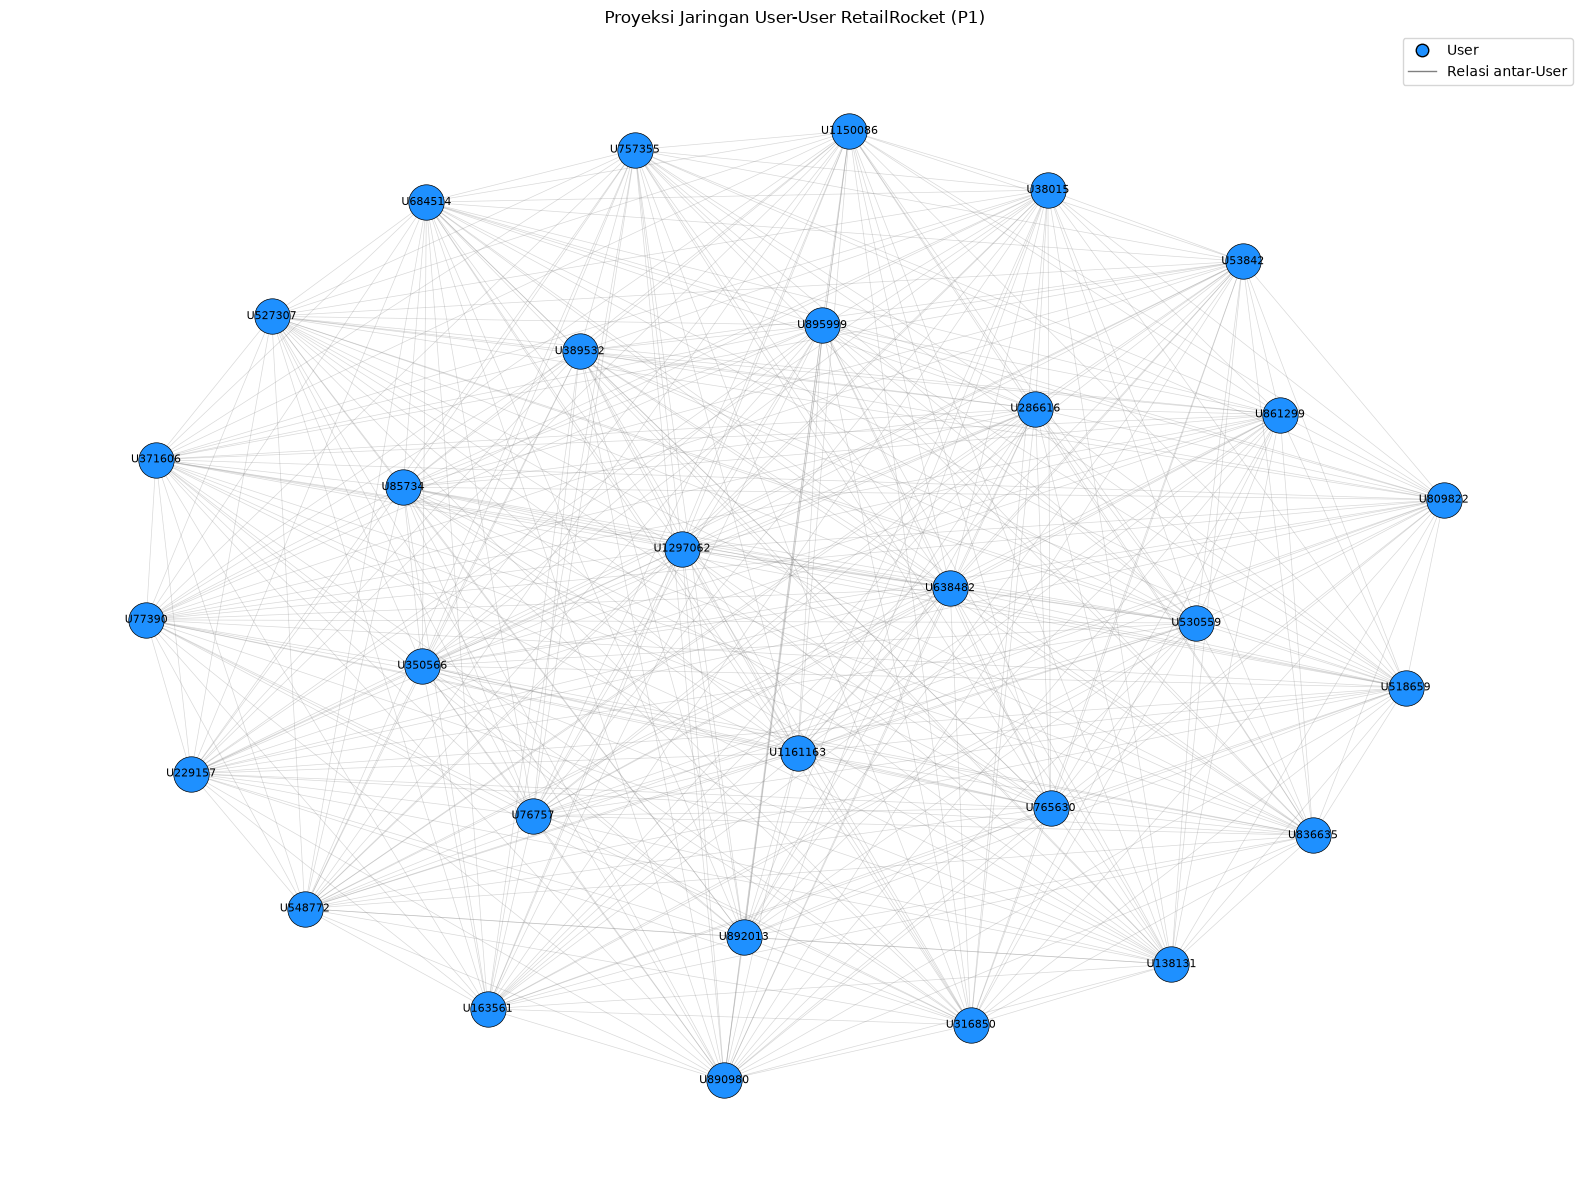


KARAKTERISTIK PROYEKSI USER-USER
Jumlah simpul User: 30
Jumlah relasi antar-User: 433
Jumlah komponen terhubung: 1
Jumlah User tanpa relasi: 0


In [ ]:
# Memilih 30 user teraktif
user_aktif = (
    df_p1.groupby("visitorid")
    .size()
    .sort_values(ascending=False)
)

top_users = user_aktif.head(30).index.tolist()

user_index = {
    user_id: idx for idx, user_id in enumerate(user_ids)
}

selected_indices = [user_index[u] for u in top_users]
vsm_user_top = vsm_user[selected_indices]

# proyeksi user-user dari vsm Perkalian matriks 
similarity_matrix = (vsm_user_top @ vsm_user_top.T).toarray()

G_user = nx.Graph()

for user in top_users:
    G_user.add_node("U" + str(user))

for i, j in combinations(range(len(top_users)), 2):
    shared_items = int(similarity_matrix[i, j])

    if shared_items > 0:
        G_user.add_edge(
            "U" + str(top_users[i]),
            "U" + str(top_users[j]),
            weight=shared_items
        )
 
pos = nx.spring_layout(
    G_user,
    seed=42,
    k=2.5,
    iterations=200,
    weight=None
)

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G_user, pos,
    edge_color="gray",
    width=0.5,
    alpha=0.3
)

nx.draw_networkx_nodes(
    G_user, pos,
    node_color="dodgerblue",
    node_size=650,
    edgecolors="black",
    linewidths=0.5
)

nx.draw_networkx_labels(
    G_user, pos,
    font_size=8
)

legend_elements = [
    Line2D(
        [0], [0], marker="o", color="w",
        label="User", markerfacecolor="dodgerblue",
        markeredgecolor="black", markersize=9
    ),
    Line2D(
        [0], [0], color="gray",
        linewidth=1, label="Relasi antar-User"
    )
]

plt.legend(handles=legend_elements)
plt.title("Proyeksi Jaringan User-User RetailRocket (P1)")
plt.axis("off")
plt.tight_layout()
plt.show()


print("\nKARAKTERISTIK PROYEKSI USER-USER")
print("Jumlah simpul User:", G_user.number_of_nodes())
print("Jumlah relasi antar-User:", G_user.number_of_edges())
print("Jumlah komponen terhubung:", nx.number_connected_components(G_user))
print("Jumlah User tanpa relasi:", len(list(nx.isolates(G_user))))

In [34]:
print("Shape VSM 30 user:", vsm_user_top.shape)

Shape VSM 30 user: (30, 200994)


Proyeksi User–User dibentuk berdasarkan kesamaan Item yang pernah diinteraksikan oleh setiap User pada data P1. Dalam jaringan ini, simpul menggambarkan User, sedangkan garis menunjukkan adanya kesamaan Item antara dua User. Berdasarkan hasil pengolahan, terdapat 30 simpul User dan 433 relasi antar-User. Jaringan memiliki satu komponen terhubung dan tidak terdapat User tanpa relasi. Hasil tersebut menunjukkan bahwa seluruh User dalam sampel memiliki hubungan dengan User lain melalui kesamaan Item.

## 5. Vector Space Modelling (VSM) Item

In [35]:
df_p1 = pd.read_csv("data/events_P1_training.csv")

df_p1["itemid"] = df_p1["itemid"].astype(str)
df_p1["visitorid"] = df_p1["visitorid"].astype(str)

item_user = (
    df_p1.groupby("itemid")["visitorid"]
    .apply(lambda x: " ".join(x))
)

vectorizer_item = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    binary=True
)

vsm_item = vectorizer_item.fit_transform(item_user)

item_ids = item_user.index.tolist()

print("KARAKTERISTIK VSM ITEM")
print("Jumlah Item:", vsm_item.shape[0])
print("Jumlah User:", vsm_item.shape[1])
print("Shape VSM Item:", vsm_item.shape)
print("Jumlah elemen bukan nol:", vsm_item.nnz)


KARAKTERISTIK VSM ITEM
Jumlah Item: 200994
Jumlah User: 979136
Shape VSM Item: (200994, 979136)
Jumlah elemen bukan nol: 1496900


Berdasarkan hasil Vector Space Modelling (VSM), matriks Item memiliki 200.994 baris dan 979.136 kolom. Setiap baris merepresentasikan satu item, sedangkan setiap kolom merepresentasikan satu pengguna. Dengan demikian, ukuran matriks VSM User adalah 200.994x979.136. Matriks tersebut memiliki 1.496.900 elemen bukan nol, yang menunjukkan adanya nilai interaksi pengguna terhadap item.


Jumlah Item untuk Visualisasi: 30
Shape VSM Item Terpilih: (30, 979136)


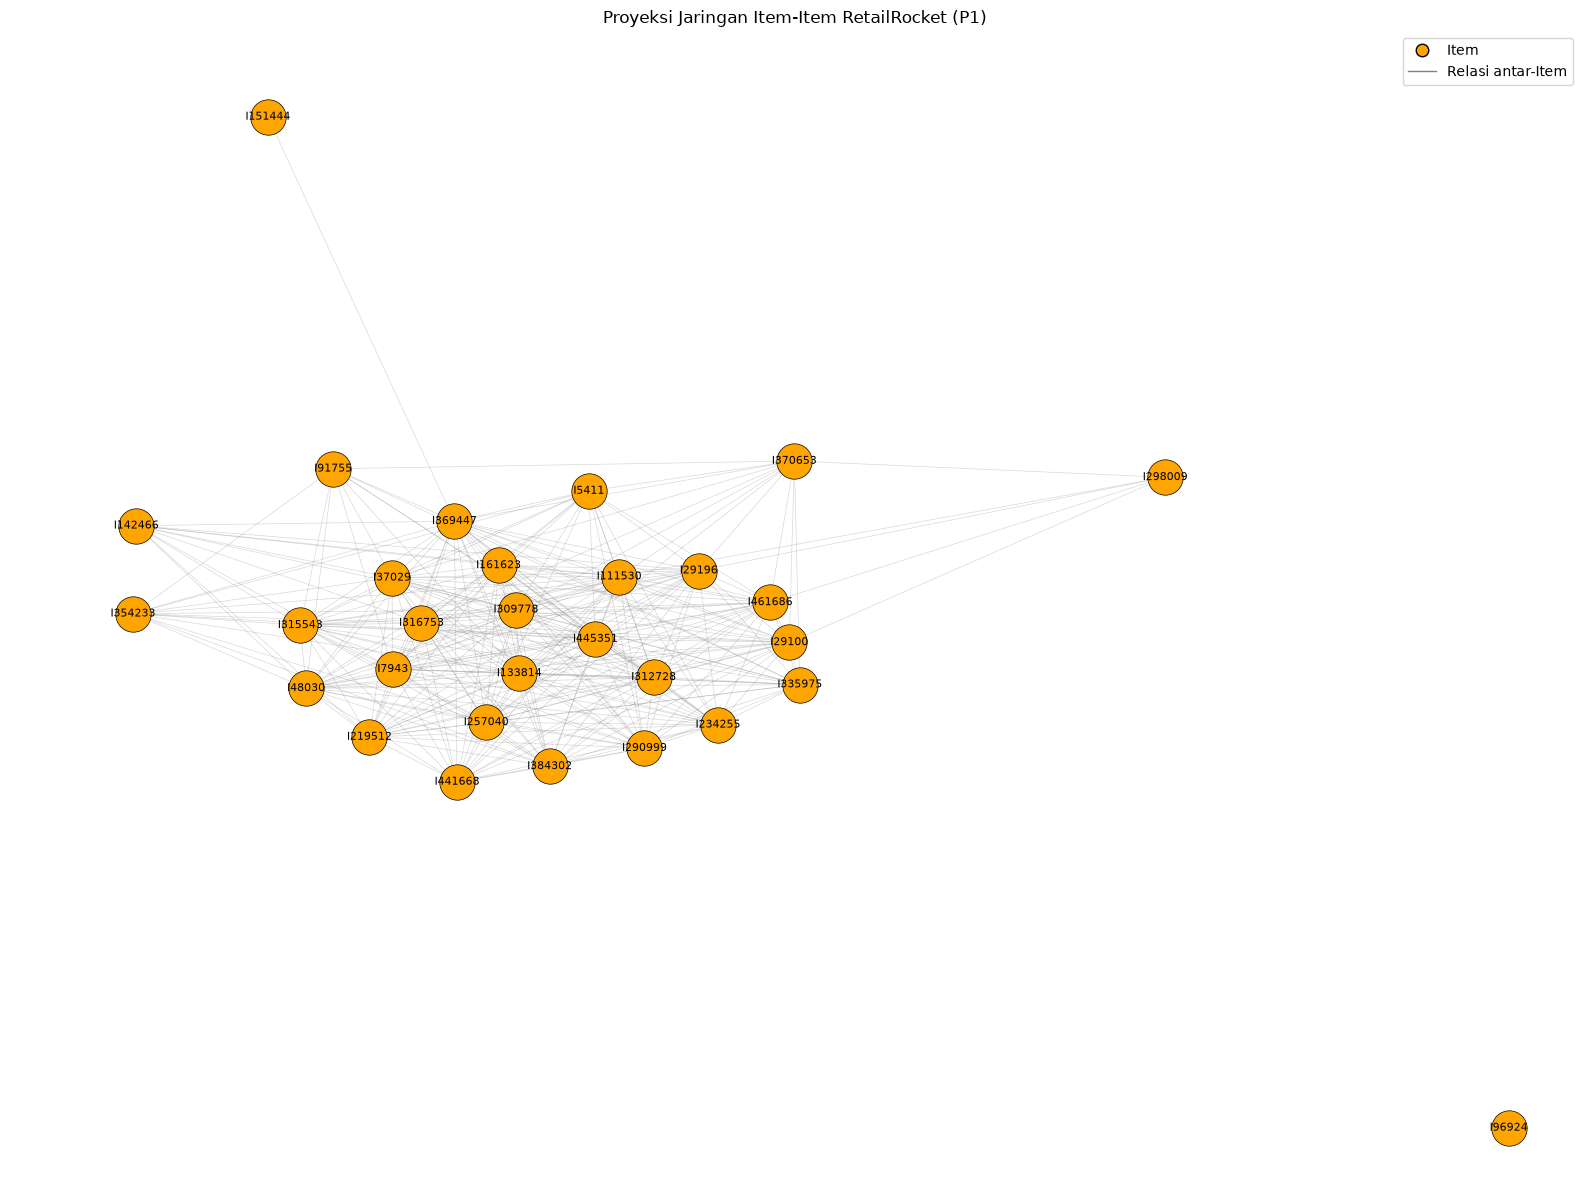


KARAKTERISTIK PROYEKSI ITEM-ITEM
Jumlah simpul Item: 30
Jumlah relasi antar-Item: 293
Jumlah komponen terhubung: 2
Jumlah Item tanpa relasi: 1


In [ ]:
item_aktif = (
    df_p1.groupby("itemid")
    .size()
    .sort_values(ascending=False)
)

top_items = [
    str(item) for item in item_aktif.head(30).index.tolist()
]

item_index = {
    item_id: idx for idx, item_id in enumerate(item_ids)
}

selected_indices = [
    item_index[item] for item in top_items
]

vsm_item_top = vsm_item[selected_indices]

print("\nJumlah Item untuk Visualisasi:", vsm_item_top.shape[0])
print("Shape VSM Item Terpilih:", vsm_item_top.shape)


similarity_matrix = (vsm_item_top @ vsm_item_top.T).toarray()


G_item = nx.Graph()

for item in top_items:
    G_item.add_node("I" + str(item))

for i, j in combinations(range(len(top_items)), 2):
    shared_users = int(similarity_matrix[i, j])

    if shared_users > 0:
        G_item.add_edge(
            "I" + str(top_items[i]),
            "I" + str(top_items[j]),
            weight=shared_users
        )

pos = nx.spring_layout(
    G_item,
    seed=42,
    k=2.5,
    iterations=200,
    weight=None
)

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G_item, pos,
    edge_color="gray",
    width=0.5,
    alpha=0.3
)

nx.draw_networkx_nodes(
    G_item, pos,
    node_color="orange",
    node_size=650,
    edgecolors="black",
    linewidths=0.5
)

nx.draw_networkx_labels(
    G_item, pos,
    font_size=8
)

legend_elements = [
    Line2D(
        [0], [0], marker="o", color="w",
        label="Item", markerfacecolor="orange",
        markeredgecolor="black", markersize=9
    ),
    Line2D(
        [0], [0], color="gray",
        linewidth=1, label="Relasi antar-Item"
    )
]

plt.legend(handles=legend_elements)
plt.title("Proyeksi Jaringan Item-Item RetailRocket (P1)")
plt.axis("off")
plt.tight_layout()
plt.show()

print("\nKARAKTERISTIK PROYEKSI ITEM-ITEM")
print("Jumlah simpul Item:", G_item.number_of_nodes())
print("Jumlah relasi antar-Item:", G_item.number_of_edges())
print("Jumlah komponen terhubung:", nx.number_connected_components(G_item))
print("Jumlah Item tanpa relasi:", len(list(nx.isolates(G_item))))

Berdasarkan hasil proyeksi Item–Item, terdapat 30 simpul item dan 293 relasi yang menunjukkan adanya keterkaitan antaritem karena pernah diakses oleh user yang sama. Jaringan ini terbagi menjadi 2 komponen terhubung, artinya terdapat dua kelompok item yang saling terhubung di dalam jaringan. Selain itu, terdapat 1 item yang tidak memiliki relasi dengan item lainnya. Hasil ini menunjukkan bahwa sebagian besar item memiliki keterkaitan dengan item lain berdasarkan kesamaan user yang berinteraksi dengannya.

## 6 Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Berdasarkan hasil eksplorasi nomor 4 dan 5, proyeksi User–User lebih baik dari segi keterhubungan jaringan karena memiliki 433 relasi dan 1 komponen terhubung. Sementara itu, proyeksi Item–Item memiliki 293 relasi dan 2 komponen yg terpisah. Hal ini menunjukkan bahwa hubungan antar-User lebih rapat, sedangkan jaringan Item–Item memiliki lebih sedikit relasi sehingga tampilannya cenderung lebih sederhana.

Dari segi efektivitas, proyeksi User–User lebih sesuai untuk menganalisis hubungan antar pengguna berdasarkan kesamaan Item yang diinteraksikan. Dari segi efisiensi visualisasi, proyeksi Item–Item lebih mudah diamati karena jumlah relasinya lebih sedikit. Dengan demikian, proyeksi User–User lebih unggul untuk melihat keterhubungan jaringan, sedangkan pilihan terbaik secara keseluruhan tetap bergantung pada tujuan analisis.

## 7.  Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python 

### Proyeksi user-user

In [43]:
print("Jumlah User:", len(top_users))

Jumlah User: 30


In [44]:
# Membentuk graf proyeksi User-User dari VSM User
G_user = nx.Graph()

for user in top_users:
    G_user.add_node(str(user))

# Menghitung Jaccard similarity antar-User
for i, j in combinations(range(len(top_users)), 2):
    items1 = set(vsm_user_top[i].nonzero()[1])
    items2 = set(vsm_user_top[j].nonzero()[1])

    irisan = items1 & items2
    gabungan = items1 | items2

    if len(irisan) > 0 and len(gabungan) > 0:
        similarity = len(irisan) / len(gabungan)

        G_user.add_edge(
            str(top_users[i]),
            str(top_users[j]),
            weight=len(irisan),
            similarity=similarity,
            shared_items=len(irisan)
        )

print("Jumlah simpul:", G_user.number_of_nodes())
print("Jumlah relasi:", G_user.number_of_edges())


Jumlah simpul: 30
Jumlah relasi: 433


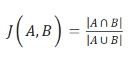

In [ ]:
hasil_similarity = []

for user1, user2, data in G_user.edges(data=True):
    hasil_similarity.append({
        "User 1": user1,
        "User 2": user2,
        "Jaccard Similarity": data["similarity"],
        "Shared Items": data["shared_items"]
    })

df_similarity = pd.DataFrame(hasil_similarity)

df_similarity = df_similarity.sort_values(
    by="Jaccard Similarity",
    ascending=False
)

print("5 Pasangan User dengan Similarity Tertinggi:")
display(df_similarity.head(5))

5 Pasangan User dengan Similarity Tertinggi:


,User 1,User 2,Jaccard Similarity,Shared Items
0,1150086,530559,0.113202,409
30,530559,371606,0.105597,266
2,1150086,371606,0.103665,379
7,1150086,1297062,0.092380,314
281,895999,85734,0.087645,166


In [46]:
URI = "bolt://localhost:7687"
AUTH = ("neo4j", "adistiebil123")

driver = GraphDatabase.driver(URI, auth=AUTH)

In [ ]:
# Menyimpan Jaccard Similarity ke Neo4j
with driver.session(database="neo4j") as session:

    for u, v, data in G_user.edges(data=True):

        session.run(
            """
            MATCH (a:Visitor {visitorId: $user1})
            MATCH (b:Visitor {visitorId: $user2})

            MERGE (a)-[r:SIMILAR_TO_JACCARD]-(b)

            SET r.similarity = $similarity,
                r.shared_items = $shared_items
            """,
            user1=int(u),
            user2=int(v),
            similarity=float(data["similarity"]),
            shared_items=int(data["shared_items"])
        )

print("Jaccard Similarity berhasil disimpan ke Neo4j!")

Jaccard Similarity berhasil disimpan ke Neo4j!


## 7a.  CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

In [ ]:
# MATCH (a:Visitor {visitorId: 530559})
#       -[r:SIMILAR_TO_JACCARD]-
#       (b:Visitor)
# RETURN
#     a.visitorId AS User_Acuan,
#     b.visitorId AS User_Lain,
#     r.similarity AS Similarity,
#     r.shared_items AS Shared_Items
# ORDER BY Similarity DESC
# LIMIT 5;

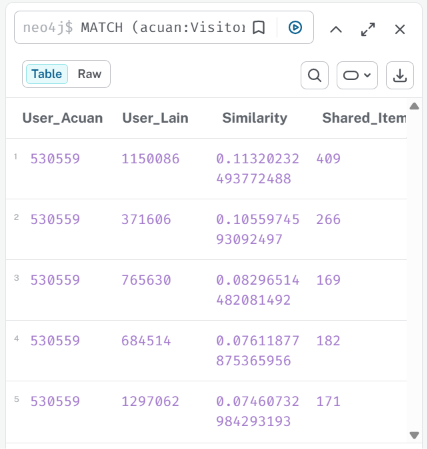

Berdasarkan hasil query Cypher dengan User 530559 sebagai User acuan, diperoleh lima User dengan nilai Jaccard Similarity tertinggi. User 1150086 memiliki nilai similarity tertinggi sebesar 0,1132 dengan 409 item yang sama. Selanjutnya, User 371606 memiliki similarity sebesar 0,1056 dengan 266 item yang sama. Hasil ini menunjukkan tingkat kemiripan item antara User acuan dan masing-masing User lainnya berdasarkan perbandingan jumlah item yang sama dengan seluruh item unik dari kedua User.

## 7b. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query nya! 

In [ ]:
# MATCH (a:Visitor {visitorId: 530559})
#       -[r:SIMILAR_TO_JACCARD]-
#       (b:Visitor)
# WITH a, b, r
# ORDER BY r.similarity DESC
# LIMIT 5
# RETURN a, r, b;

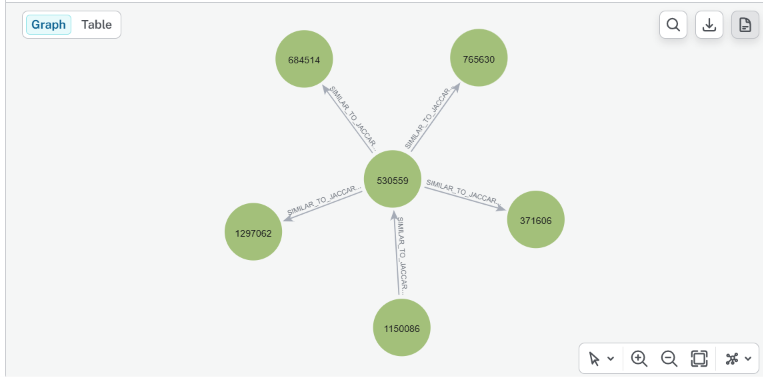

Graf menunjukkan hubungan antara User acuan 530559 dengan lima User yang memiliki nilai Jaccard Similarity tertinggi. Setiap simpul merepresentasikan User, sedangkan setiap relasi menunjukkan kemiripan berdasarkan item yang diinteraksikan. User 1150086 memiliki kemiripan tertinggi sebesar 0,1132 dengan 409 item yang sama. Visualisasi ini memperlihatkan hasil penyimpanan nilai similarity pada graf Neo4j sehingga hubungan antar-User dapat diamati secara langsung.

## 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity! 

In [4]:
# Sebelum perhitungan similarity
# MATCH (v:Visitor)-[r]->(i:Item)
# RETURN v, r, i
# LIMIT 50;

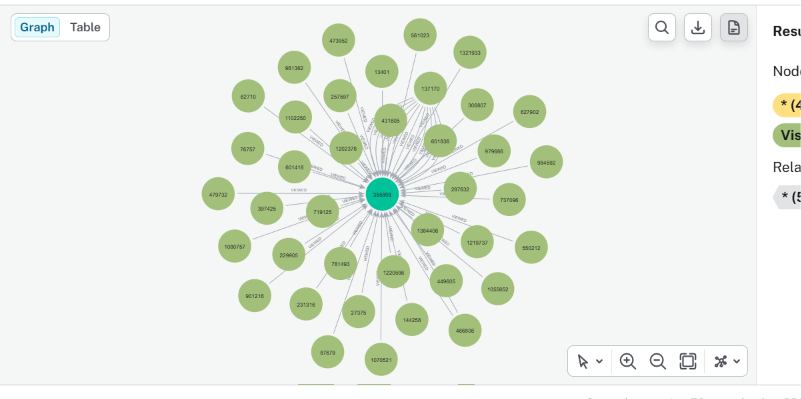

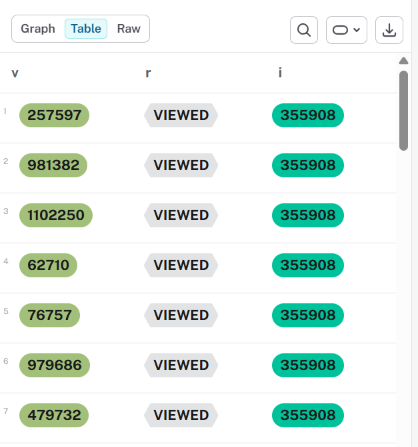

In [ ]:
# MATCH (a:Visitor {visitorId: 530559})
#       -[r:SIMILAR_TO_JACCARD]-
#       (b:Visitor)
# WITH a, b, r
# ORDER BY r.similarity DESC
# LIMIT 5
# RETURN a, r, b;

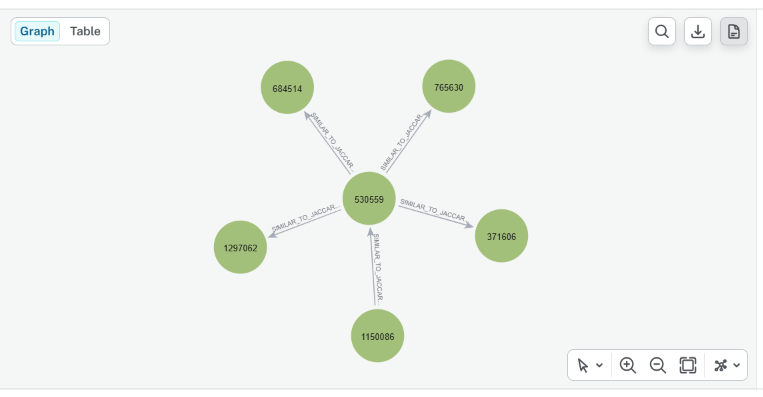

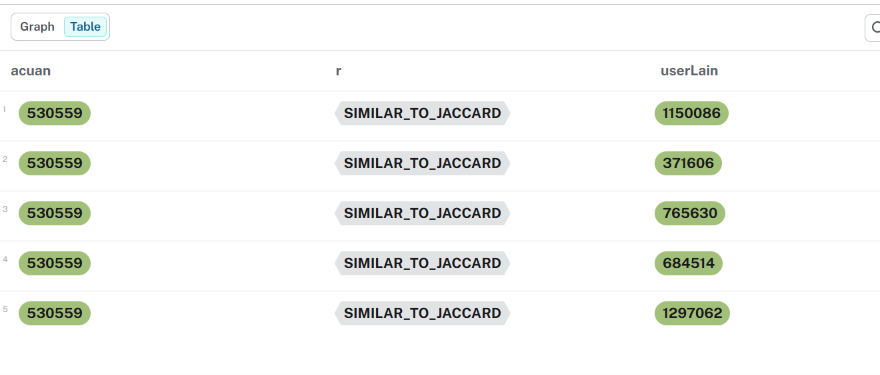

Sebelum perhitungan similarity, graf menampilkan hubungan antara Visitor dan Item berdasarkan aktivitas pengguna. Setelah perhitungan similarity, relasi SIMILAR_TO_JACCARD ditambahkan untuk menunjukkan kemiripan antar-User berdasarkan item yang pernah diinteraksikan. Hasilnya, User acuan 530559 terhubung dengan lima User yang memiliki nilai similarity tertinggi.

## 2.2 Analytics

## 1.  Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi)

### Memilih user secara acak

In [8]:
from collections import defaultdict
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

In [25]:
# Menyamakan format ID untuk pencocokan
df_p1["visitorid"] = df_p1["visitorid"].astype(str)
df_p1["itemid"] = df_p1["itemid"].astype(str)

jumlah_item_user = (
    df_p1.groupby("visitorid")["itemid"].nunique()
)

kandidat_user = jumlah_item_user[
    jumlah_item_user >= 5
].index.to_numpy()

daftar_user_vsm = np.array(
    [str(u) for u in user_item.index]
)

# Memetakan ID user ke baris VSM
user_index = {
    user: idx for idx, user in enumerate(daftar_user_vsm)
}

kandidat_user = np.array([
    u for u in kandidat_user if u in user_index
])

if len(kandidat_user) < 2:
    raise ValueError(
        "Jumlah kandidat user kurang dari 2 untuk menjalankan KNN."
    )

rng = np.random.default_rng(42)
user_terpilih = str(rng.choice(kandidat_user))

print("User terpilih:", user_terpilih)
print(
    "Jumlah item unik:",
    jumlah_item_user.loc[user_terpilih]
)

User terpilih: 1113239
Jumlah item unik: 19


In [ ]:
posisi_aktif = np.array([
    user_index[u] for u in kandidat_user
])

vsm_aktif = normalize(
    vsm_user[posisi_aktif],
    norm="l2"
)

daftar_user_aktif = kandidat_user

posisi_user = np.where(
    daftar_user_aktif == user_terpilih
)[0][0]

# KNN: cari maksimal 5 tetangga selain user acuan
jumlah_tetangga = min(6, len(daftar_user_aktif))

knn = NearestNeighbors(
    n_neighbors=jumlah_tetangga,
    metric="cosine",
    algorithm="brute"
)

knn.fit(vsm_aktif)

jarak, indeks = knn.kneighbors(
    vsm_aktif[posisi_user],
    n_neighbors=jumlah_tetangga
)

hasil_knn = []

for d, idx in zip(jarak[0], indeks[0]):
    user_tetangga = str(daftar_user_aktif[idx])

    if user_tetangga == user_terpilih:
        continue

    hasil_knn.append({
        "User": user_tetangga,
        "Cosine Similarity": round(float(1 - d), 6)
    })

    if len(hasil_knn) == 5:
        break

df_knn = pd.DataFrame(hasil_knn)

print("\n5 Tetangga Terdekat:")
print(df_knn.to_string(index=False))

item_user_acuan = set(
    df_p1.loc[
        df_p1["visitorid"] == user_terpilih,
        "itemid"
    ].unique()
)

# Kumpulkan item baru dari tetangga
item_tetangga = defaultdict(set)

for user in df_knn["User"]:
    item_user = set(
        df_p1.loc[
            df_p1["visitorid"] == user,
            "itemid"
        ].unique()
    )

    item_baru = item_user - item_user_acuan

    for item in item_baru:
        item_tetangga[item].add(user)

hasil_rekomendasi = sorted(
    item_tetangga.items(),
    key=lambda x: (-len(x[1]), x[0])
)[:3]

df_rekomendasi = pd.DataFrame([
    {
        "Item ID": item,
        "Jumlah Tetangga": len(tetangga),
        "User yang Berinteraksi": ", ".join(sorted(tetangga))
    }
    for item, tetangga in hasil_rekomendasi
])

print("\n3 Item Rekomendasi:")
print(df_rekomendasi.to_string(index=False))



5 Tetangga Terdekat:
   User  Cosine Similarity
 316101           0.410391
1008448           0.307794
 562081           0.307794
 916269           0.280976
1101034           0.243332

3 Item Rekomendasi:
Item ID  Jumlah Tetangga  User yang Berinteraksi
 161623                3 1101034, 562081, 916269
 197642                2         1008448, 916269
 463663                2         1101034, 316101


Berdasarkan hasil penerapan metode K-Nearest Neighbors (KNN) dengan \(k=5\), pengguna yang terpilih secara acak adalah User 1113239, yang memiliki 19 item unik pada data training. Lima tetangga terdekat ditentukan berdasarkan nilai Cosine Similarity, dengan nilai tertinggi sebesar 0,410391 pada User 316101. Selanjutnya, sistem menghasilkan tiga rekomendasi item, yaitu Item 161623, yang berinteraksi dengan tiga tetangga, serta Item 197642 dan Item 463663, yang masing-masing berinteraksi dengan dua tetangga. Rekomendasi ini ditentukan berdasarkan frekuensi kemunculan item pada riwayat interaksi kelima tetangga, sehingga item yang didukung oleh lebih banyak tetangga diprioritaskan.

## 2.  Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:  

### 2a. Menghitung Hit@5

In [ ]:
df_p2 = pd.read_csv("data/events_P2_testing.csv")

df_p2["visitorid"] = pd.to_numeric(
    df_p2["visitorid"], errors="coerce"
)

print("Jumlah data P2:", len(df_p2))
print(df_p2.head())

Jumlah data P2: 826393
       timestamp  visitorid event  itemid  transactionid
0  1438560971338     535735  view  193304            NaN
1  1438566163515     102534  view  290664            NaN
2  1438561051747     836544  view   59020            NaN
3  1438560744859    1289277  view  225565            NaN
4  1438564551297     798002  view  353482            NaN


In [28]:
user_terpilih = str(user_terpilih)
print("User acuan:", user_terpilih)

item_relevan = set(
    df_p2.loc[
        df_p2["visitorid"] == int(user_terpilih),
        "itemid"
    ].astype(str)
)

item_rekomendasi = (
    df_rekomendasi["Item ID"].astype(str).tolist()[:5]
)

# Mencari item rekomendasi yang cocok dengan data P2
item_cocok = set(item_rekomendasi) & item_relevan

# Menghitung Hit@5
hit_at_5 = int(len(item_cocok) > 0)

print("Jumlah item relevan pada P2:", len(item_relevan))
print("Item rekomendasi Top-3:", item_rekomendasi)
print("Item yang cocok:", item_cocok)
print("Hit@5:", hit_at_5)
print("Item relevan:", item_relevan)

User acuan: 1113239
Jumlah item relevan pada P2: 3
Item rekomendasi Top-3: ['161623', '197642', '463663']
Item yang cocok: set()
Hit@5: 0
Item relevan: {'134357', '64970', '312842'}


In [ ]:
print("User acuan:", user_terpilih)

# Memeriksa interaksi User acuan pada P1 dan P2
print(
    "Interaksi pada P1:",
    (df_p1["visitorid"] == user_terpilih).sum()
)

print(
    "Interaksi pada P2:",
    (df_p2["visitorid"] == user_terpilih).sum()
)

display(df_rekomendasi)

User acuan: 1113239
Interaksi pada P1: 20
Interaksi pada P2: 0


,Item ID,Jumlah Tetangga,User yang Berinteraksi
0,161623,3,"1101034, 562081, 916269"
1,197642,2,"1008448, 916269"
2,463663,2,"1101034, 316101"


Berdasarkan hasil analisis, User 1113239 memiliki 20 interaksi pada periode training (P1), tetapi tidak memiliki interaksi pada periode testing (P2). Dengan menggunakan metode K-Nearest Neighbors (KNN) dengan \(k=5\), sistem menghasilkan tiga rekomendasi item, yaitu Item 161623, Item 197642, dan Item 463663. Item 161623 menjadi rekomendasi utama karena berinteraksi dengan tiga tetangga terdekat, sedangkan Item 197642 dan Item 463663 masing-masing berinteraksi dengan dua tetangga.

### 2.b menghitung NDCG@5 

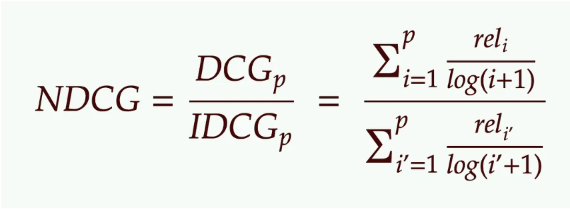

In [30]:
# Hitung NDCG@5 pada item relevan
if len(item_relevan) == 0:
    print("User acuan:", user_terpilih)
    print("NDCG@5: Tidak dapat dievaluasi")
    print("Alasan: User acuan tidak memiliki interaksi pada P2.")

else:
    relevansi = [
        1 if item in item_relevan else 0
        for item in item_rekomendasi[:5]
    ]

    dcg = sum(
        rel / np.log2(i + 2)
        for i, rel in enumerate(relevansi)
    )

    idcg = sum(
        1 / np.log2(i + 2)
        for i in range(min(len(item_relevan), 5))
    )

    ndcg_at_5 = dcg / idcg if idcg > 0 else 0

    print("User acuan:", user_terpilih)
    print("Relevansi:", relevansi)
    print("DCG@5:", round(dcg, 4))
    print("IDCG@5:", round(idcg, 4))
    print("NDCG@5:", round(ndcg_at_5, 4))

User acuan: 1113239
Relevansi: [0, 0, 0]
DCG@5: 0.0
IDCG@5: 2.1309
NDCG@5: 0.0


Kode tersebut digunakan untuk menghitung nilai NDCG@5 pada User 1113239 dengan membandingkan item rekomendasi terhadap item yang diakses pengguna pada data pengujian P2. Hasil relevansi [0, 0, 0] menunjukkan bahwa ketiga item rekomendasi tidak ditemukan dalam interaksi pengguna pada P2. Oleh karena itu, nilai DCG@5 adalah 0.0, sedangkan IDCG@5 sebesar 2.1309 merupakan nilai ideal jika item relevan berada pada urutan terbaik. Hasil perhitungan menghasilkan NDCG@5 sebesar 0.0, yang berarti tidak ada item rekomendasi yang cocok dengan interaksi pengguna pada data pengujian.